In [6]:
%load_ext autoreload
%autoreload 2

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import Pipeline
import joblib

# Conectar con la carpeta src
sys.path.append(os.path.abspath('..'))
from src.transformadores import LimpiadorFormatosKaggle, CalculadorDistancia
from src.pipeline import construir_pipeline_preprocesamiento

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
print("=====================================================================")
print("                 CARGA Y PREPARACIÓN DE DATOS")
print("=====================================================================\n")

df_train = pd.read_csv('../data/processed/train_processed.csv')
df_test = pd.read_csv('../data/processed/test_processed.csv')

limpiador = LimpiadorFormatosKaggle()
calculador = CalculadorDistancia()

df_train_final = calculador.transform(limpiador.transform(df_train))
df_test_final = calculador.transform(limpiador.transform(df_test))

X_train = df_train_final.drop(columns=['Time_taken(min)'])
y_train = df_train_final['Time_taken(min)'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)

X_test = df_test_final.drop(columns=['Time_taken(min)'])
y_test = df_test_final['Time_taken(min)'].astype(str).str.extract(r'(\d+\.?\d*)')[0].astype(float)

print("Datos listos para RandomForest.")

                 CARGA Y PREPARACIÓN DE DATOS

Datos listos para RandomForest.


In [8]:
print("=====================================================================")
print("         ENTRENAMIENTO Y VALIDACIÓN CRUZADA (RANDOM FOREST)")
print("=====================================================================\n")

# Instanciamos el Random Forest. Usaremos 50 árboles (n_estimators=50)
# para balancear la precisión con el tiempo de entrenamiento en tu máquina.
pipeline_rf = Pipeline(steps=[
    ('preprocesador', construir_pipeline_preprocesamiento()),
    ('modelo_rf', RandomForestRegressor(n_estimators=50, max_depth=15, min_samples_split=5, random_state=42, n_jobs=-1))
])

print("Entrenando Random Forest...")
pipeline_rf.fit(X_train, y_train)

# Evaluación en Test Set
y_pred_test_rf = pipeline_rf.predict(X_test)
mae_rf = mean_absolute_error(y_test, y_pred_test_rf)
r2_rf = r2_score(y_test, y_pred_test_rf)

print(f"--- MÉTRICAS TEST SET ---")
print(f"MAE: {mae_rf:.2f} minutos")
print(f"R2:  {r2_rf:.4f}\n")

print("Ejecutando K-Fold Cross Validation (K=5)...")
scores_mae_rf = -cross_val_score(pipeline_rf, X_train, y_train, cv=5, scoring='neg_mean_absolute_error')
print(f"MAE Promedio K-Fold: {scores_mae_rf.mean():.2f} minutos (+/- {scores_mae_rf.std():.2f} min)")

         ENTRENAMIENTO Y VALIDACIÓN CRUZADA (RANDOM FOREST)

Entrenando Random Forest...
--- MÉTRICAS TEST SET ---
MAE: 3.17 minutos
R2:  0.8180

Ejecutando K-Fold Cross Validation (K=5)...
MAE Promedio K-Fold: 3.17 minutos (+/- 0.03 min)


             DIAGNÓSTICO VISUAL DE RANDOM FOREST



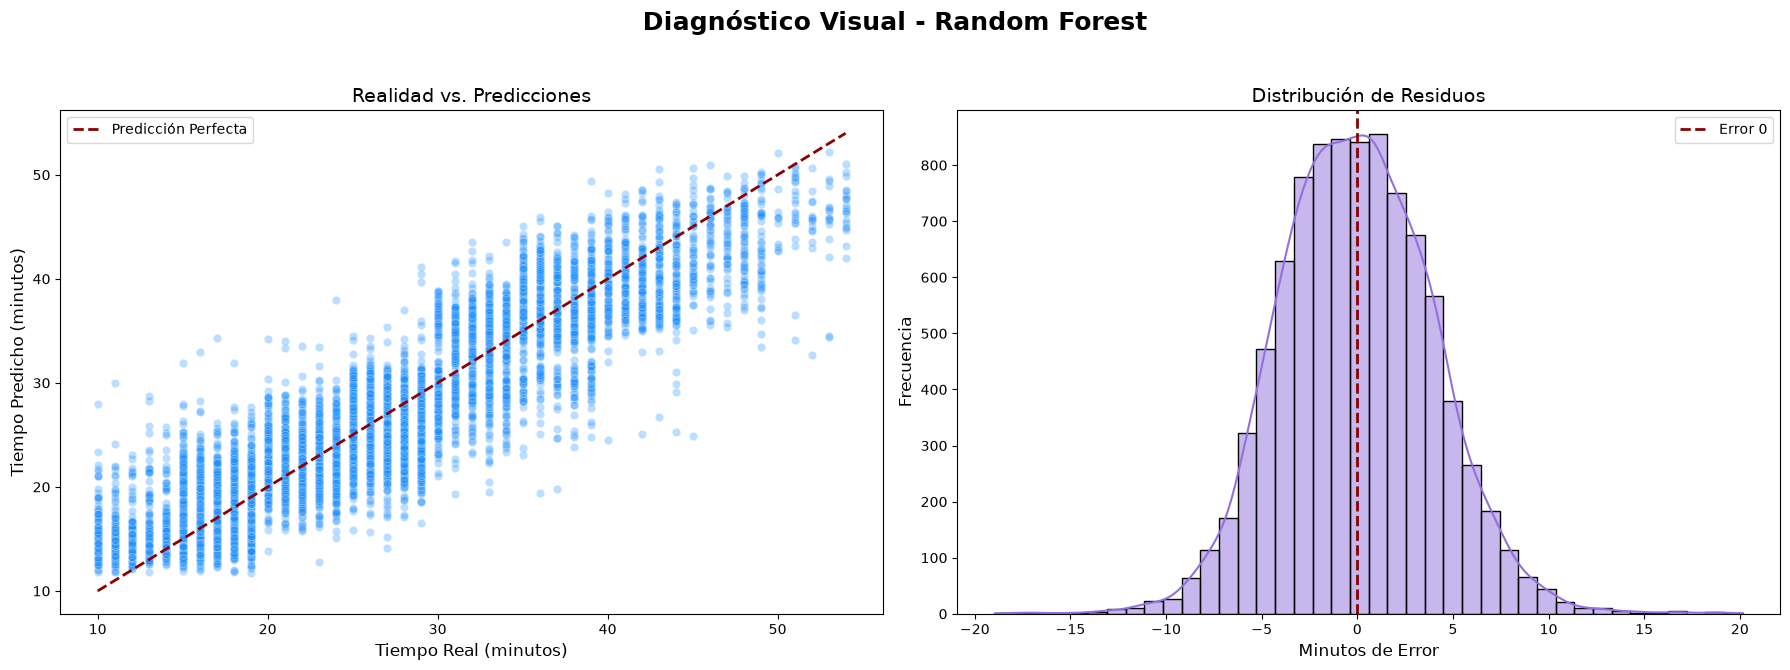

In [9]:
print("=====================================================================")
print("             DIAGNÓSTICO VISUAL DE RANDOM FOREST")
print("=====================================================================\n")

residuos_rf = y_test - y_pred_test_rf

fig, ax = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Diagnóstico Visual - Random Forest', fontsize=18, fontweight='bold')

# Gráfico 1: Real vs. Predicho
sns.scatterplot(x=y_test, y=y_pred_test_rf, alpha=0.3, color='dodgerblue', ax=ax[0])
min_val = min(y_test.min(), y_pred_test_rf.min())
max_val = max(y_test.max(), y_pred_test_rf.max())
ax[0].plot([min_val, max_val], [min_val, max_val], color='darkred', linestyle='--', linewidth=2, label='Predicción Perfecta')
ax[0].set_title('Realidad vs. Predicciones', fontsize=14)
ax[0].set_xlabel('Tiempo Real (minutos)', fontsize=12)
ax[0].set_ylabel('Tiempo Predicho (minutos)', fontsize=12)
ax[0].legend()

# Gráfico 2: Campana de Errores
sns.histplot(residuos_rf, kde=True, color='mediumpurple', bins=40, ax=ax[1])
ax[1].axvline(0, color='darkred', linestyle='--', linewidth=2, label='Error 0')
ax[1].set_title('Distribución de Residuos', fontsize=14)
ax[1].set_xlabel('Minutos de Error', fontsize=12)
ax[1].set_ylabel('Frecuencia', fontsize=12)
ax[1].legend()

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [10]:
print("=====================================================================")
print("         SERIALIZACIÓN Y VEREDICTO ")
print("=====================================================================\n")

ruta_modelo_rf = os.path.join('..', 'models', 'modelo_random_forest.joblib')
joblib.dump(pipeline_rf, ruta_modelo_rf)
print(f"✓ Modelo Random Forest serializado en:\n{ruta_modelo_rf}\n")


         SERIALIZACIÓN Y VEREDICTO 

✓ Modelo Random Forest serializado en:
..\models\modelo_random_forest.joblib

